In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [3]:
ds=pd.read_csv("cgpa.csv")
ds.head(3)

,CGPA,Package_LPA
0,5.03,7.16
1,5.03,8.87
2,5.05,6.42


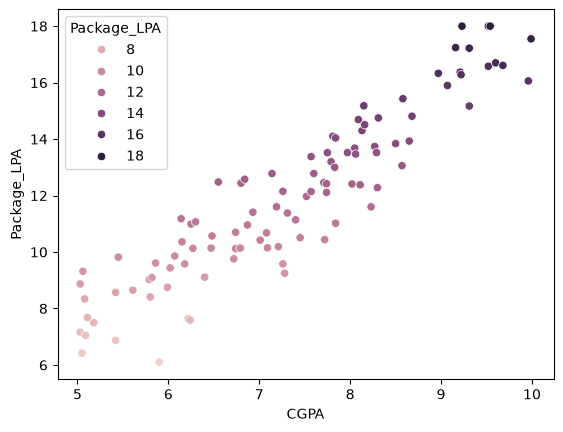

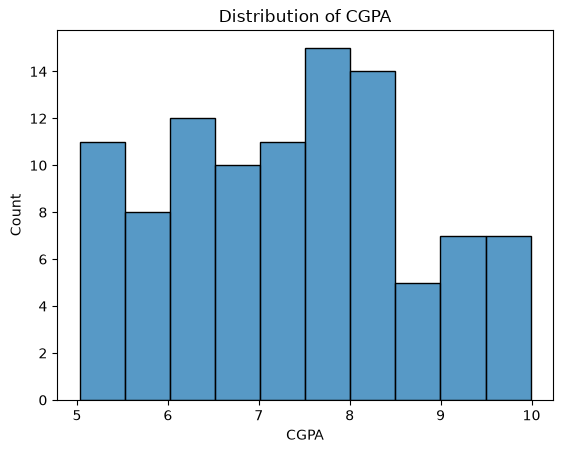

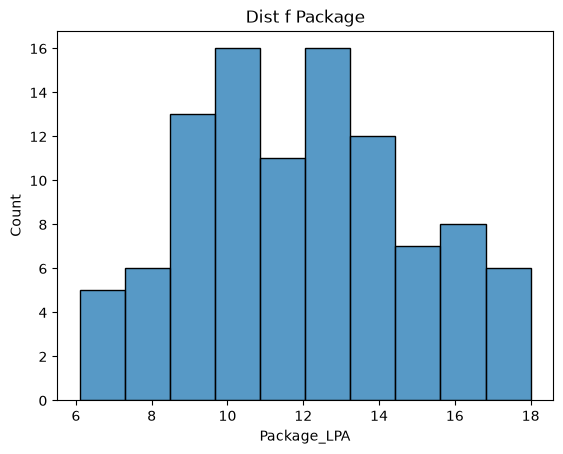

In [35]:
sns.scatterplot(x="CGPA",y="Package_LPA",data=ds,hue="Package_LPA")
plt.show()

sns.histplot(data=ds, x="CGPA", bins=10)
plt.title("Distribution of CGPA")
plt.show()

sns.histplot(data=ds, x="Package_LPA", bins=10)
plt.title("Dist f Package")
plt.show()



In [5]:
x=ds.iloc[:,-1]
y=ds["Package_LPA"]



In [8]:
new_data=ds.head(10)
x_new=new_data.iloc[:,-1]
y_new=new_data["Package_LPA"]
#importing all algo 
from sklearn.model_selection import LeaveOneOut,LeavePOut,StratifiedKFold,KFold


In [11]:
#1-------------
lo=LeaveOneOut()
for train , test in lo.split(x_new,y_new):
    print(train,test)



[1 2 3 4 5 6 7 8 9] [0]
[0 2 3 4 5 6 7 8 9] [1]
[0 1 3 4 5 6 7 8 9] [2]
[0 1 2 4 5 6 7 8 9] [3]
[0 1 2 3 5 6 7 8 9] [4]
[0 1 2 3 4 6 7 8 9] [5]
[0 1 2 3 4 5 7 8 9] [6]
[0 1 2 3 4 5 6 8 9] [7]
[0 1 2 3 4 5 6 7 9] [8]
[0 1 2 3 4 5 6 7 8] [9]


In [14]:
#2----------
lp=LeavePOut(p=2)#here p----means the number of data points left out for testing in each iteration
for train , test in lp.split(x_new,y_new):
    print(train,test)

[2 3 4 5 6 7 8 9] [0 1]
[1 3 4 5 6 7 8 9] [0 2]
[1 2 4 5 6 7 8 9] [0 3]
[1 2 3 5 6 7 8 9] [0 4]
[1 2 3 4 6 7 8 9] [0 5]
[1 2 3 4 5 7 8 9] [0 6]
[1 2 3 4 5 6 8 9] [0 7]
[1 2 3 4 5 6 7 9] [0 8]
[1 2 3 4 5 6 7 8] [0 9]
[0 3 4 5 6 7 8 9] [1 2]
[0 2 4 5 6 7 8 9] [1 3]
[0 2 3 5 6 7 8 9] [1 4]
[0 2 3 4 6 7 8 9] [1 5]
[0 2 3 4 5 7 8 9] [1 6]
[0 2 3 4 5 6 8 9] [1 7]
[0 2 3 4 5 6 7 9] [1 8]
[0 2 3 4 5 6 7 8] [1 9]
[0 1 4 5 6 7 8 9] [2 3]
[0 1 3 5 6 7 8 9] [2 4]
[0 1 3 4 6 7 8 9] [2 5]
[0 1 3 4 5 7 8 9] [2 6]
[0 1 3 4 5 6 8 9] [2 7]
[0 1 3 4 5 6 7 9] [2 8]
[0 1 3 4 5 6 7 8] [2 9]
[0 1 2 5 6 7 8 9] [3 4]
[0 1 2 4 6 7 8 9] [3 5]
[0 1 2 4 5 7 8 9] [3 6]
[0 1 2 4 5 6 8 9] [3 7]
[0 1 2 4 5 6 7 9] [3 8]
[0 1 2 4 5 6 7 8] [3 9]
[0 1 2 3 6 7 8 9] [4 5]
[0 1 2 3 5 7 8 9] [4 6]
[0 1 2 3 5 6 8 9] [4 7]
[0 1 2 3 5 6 7 9] [4 8]
[0 1 2 3 5 6 7 8] [4 9]
[0 1 2 3 4 7 8 9] [5 6]
[0 1 2 3 4 6 8 9] [5 7]
[0 1 2 3 4 6 7 9] [5 8]
[0 1 2 3 4 6 7 8] [5 9]
[0 1 2 3 4 5 8 9] [6 7]
[0 1 2 3 4 5 7 9] [6 8]
[0 1 2 3 4 5 7 8

In [18]:
#3----------------k fold
kf=KFold(n_splits=5)#n_split tell how many sub sets 
for train , test in kf.split(x_new,y_new):
    print(train,test)

[2 3 4 5 6 7 8 9] [0 1]
[0 1 4 5 6 7 8 9] [2 3]
[0 1 2 3 6 7 8 9] [4 5]
[0 1 2 3 4 5 8 9] [6 7]
[0 1 2 3 4 5 6 7] [8 9]


In [20]:
#4----------------stratified k fold 
#works on unbalanced dataset 
#only when classification 
#all class will be in validation dataset 
'''
---------------------------------------------
skf=StratifiedKFold(n_splits=5)
for train , test in skf.split(x_new,y_new):
    print(train,test)                                '''

'\n---------------------------------------------\nskf=StratifiedKFold(n_splits=5)\nfor train , test in skf.split(x_new,y_new):\n    print(train,test)                                '

In [ ]:
#to check accuaracy
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
p=cross_val_score(LinearRegression(),[x],[y],cv=KFold(n_splits=1))



ValueError: k-fold cross-validation requires at least one train/test split by setting n_splits=2 or more, got n_splits=1.